# Биномиальное, Пуассон и нормальное распределения — на практике для SPC
### Lois binomiale, de Poisson et normale — pratique pour la MSP (Maîtrise Statistique des Procédés)

Ноутбук для контролёра качества. Каждый блок: код → график → **«Что я вижу и почему это важно»**.

**Установка (один раз, в терминале):**
```
pip install numpy scipy pandas matplotlib jupyter
```
Запуск: `jupyter notebook spc_distributions.ipynb` → меню *Run → Run All Cells*.
Все случайные числа идут от одного генератора с фиксированным `seed`, поэтому при «Run All» результаты всегда одинаковые.

---

### Главное различие, которое стоит запомнить до всего остального

| Вопрос, который вы задаёте детали | Что считаем | Распределение | По-французски |
|---|---|---|---|
| «Годна или негодна?» (да/нет) | число **бракованных деталей** из *n* проверенных | **биномиальное** | *défectueux / non-conformes* → loi binomiale |
| «Сколько на ней дефектов?» | число **дефектов** (царапин, раковин, остановок…) | **Пуассон** | *défauts / non-conformités* → loi de Poisson |
| «Какой у неё размер?» | **измерение** (мм, Ra, Н·м…) | **нормальное** (часто) | *données par variables (mesures)* → loi normale |

Первые две — **данные по атрибутам** (*données par attributs*): мы *считаем*. Третье — **данные по переменным** (*données par variables*): мы *измеряем*.

## 0. Подготовка: импорты, генератор случайных чисел, стиль графиков

In [8]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

# Один генератор на весь ноутбук. Фиксированный seed → воспроизводимые результаты.
rng = np.random.default_rng(seed=2024)

# Цвета: синий = симуляция (то, что «намерили»), оранжевый = теория (формула),
# красный = границы (допуска или контроля), серый = центральная линия.
C_SIM, C_THEO, C_LIM, C_CL, C_ALT = "#2a78d6", "#eb6834", "#d03b3b", "#52514e", "#1baf7a"

plt.rcParams.update({
    "figure.figsize": (10, 4.5),
    "figure.dpi": 100,
    "axes.grid": True,
    "grid.color": "#e1e0d9",
    "grid.linewidth": 0.6,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.edgecolor": "#c3c2b7",
    "axes.titleweight": "bold",
    "font.size": 10,
})
pd.set_option("display.float_format", lambda x: f"{x:,.4f}")

---
## 1. БИНОМИАЛЬНОЕ РАСПРЕДЕЛЕНИЕ (*loi binomiale*)

**Когда:** берём **n** деталей, каждая независимо бракованная с вероятностью **p**. Считаем **X** = число бракованных.
X может быть только 0, 1, 2, …, n — **есть верхний предел** (больше n брака не бывает).

- среднее = **n·p**
- дисперсия = **n·p·(1−p)** → σ = √(n·p·(1−p))

### 1.1 Симуляция: 1000 партий по 50 деталей, брак 2 %

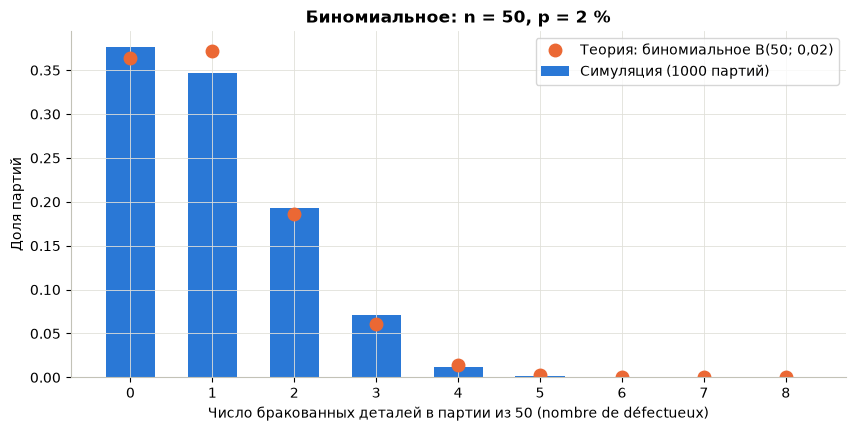

Среднее:   симуляция 0.999   | теория n·p = 1.000
Дисперсия: симуляция 0.978   | теория n·p·(1−p) = 0.980


In [9]:
n, p = 50, 0.02
N_LOTS = 1000

# Симуляция: для каждой из 1000 партий «бросаем монетку» 50 раз с вероятностью брака 2 %.
# rng.binomial делает ровно это и сразу возвращает число бракованных в каждой партии.
defects = rng.binomial(n, p, size=N_LOTS)

k = np.arange(0, 9)                               # возможные значения: 0..8 бракованных
observed = np.bincount(defects, minlength=k.size)[:k.size] / N_LOTS   # доля партий с k браками
theory = stats.binom.pmf(k, n, p)                 # теоретическая вероятность P(X = k)

fig, ax = plt.subplots()
ax.bar(k, observed, width=0.6, color=C_SIM, label="Симуляция (1000 партий)")
ax.plot(k, theory, "o", color=C_THEO, ms=9, label="Теория: биномиальное B(50; 0,02)")
ax.set_xticks(k)
ax.set_xlabel("Число бракованных деталей в партии из 50 (nombre de défectueux)")
ax.set_ylabel("Доля партий")
ax.set_title("Биномиальное: n = 50, p = 2 %")
ax.legend()
plt.show()

print(f"Среднее:   симуляция {defects.mean():.3f}   | теория n·p = {n*p:.3f}")
print(f"Дисперсия: симуляция {defects.var(ddof=1):.3f}   | теория n·p·(1−p) = {n*p*(1-p):.3f}")

In [10]:
# Вероятности, которые чаще всего нужны на практике
P0 = stats.binom.pmf(0, n, p)          # ни одной бракованной
P1 = stats.binom.pmf(1, n, p)          # ровно одна
P2plus = stats.binom.sf(1, n, p)       # sf(1) = P(X > 1) = P(X ≥ 2)

pd.DataFrame({
    "Теория": [P0, P1, P2plus],
    "Симуляция": [(defects == 0).mean(), (defects == 1).mean(), (defects >= 2).mean()],
}, index=["P(0)", "P(1)", "P(≥2)"])

,Теория,Симуляция
P(0),0.3642,0.3760
P(1),0.3716,0.3470
P(≥2),0.2642,0.2770


**Что я вижу.** Синие столбики (симуляция) почти совпадают с оранжевыми точками (формула). В среднем на партию приходится 1 бракованная деталь, но:
- **~36 % партий не содержат ни одной** бракованной детали,
- ~37 % — ровно одну,
- ~26 % — две и больше.

**Почему это важно для контроля.** Процесс *одинаковый* во всех 1000 партиях, а результат прыгает от 0 до 4–5 брака. Если сегодня 0, а вчера 3 — **это ещё не значит, что процесс изменился**. Именно эту «естественную» изменчивость и измеряют границы карты p. И ещё: распределение **несимметрично** — слева стена (меньше нуля нельзя), справа хвост.

### 1.2 Как меняется форма при разных p

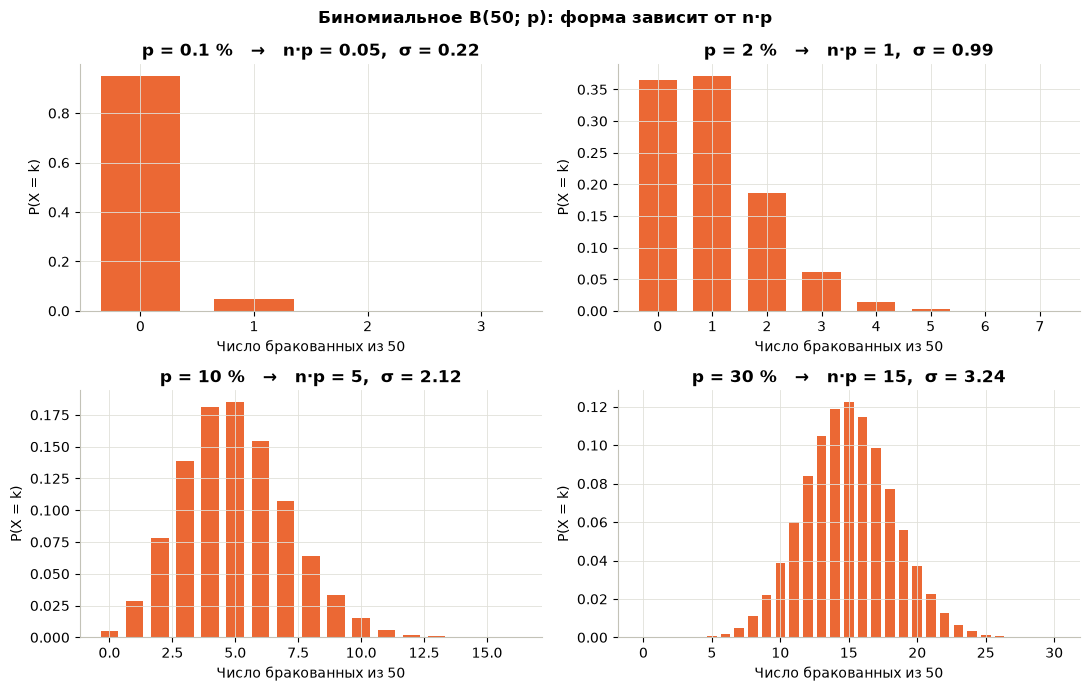

In [31]:
fig, axes = plt.subplots(2, 2, figsize=(11, 7))
for ax, p_ in zip(axes.ravel(), [0.001, 0.02, 0.10, 0.30]):
    mu, sd = n * p_, np.sqrt(n * p_ * (1 - p_))
    kmax = int(min(n, mu + 4 * sd + 3))          # показываем только интересную часть оси
    kk = np.arange(0, kmax + 1)
    ax.bar(kk, stats.binom.pmf(kk, n, p_), width=0.7, color=C_THEO)
    ax.set_title(f"p = {p_*100:g} %   →   n·p = {mu:g},  σ = {sd:.2f}")
    ax.set_xlabel("Число бракованных из 50")
    ax.set_ylabel("P(X = k)")
    if kmax <= 12:
        ax.set_xticks(kk)
fig.suptitle("Биномиальное B(50; p): форма зависит от n·p", fontweight="bold")
fig.tight_layout()
plt.show()

**Что я вижу.**
- **p = 0,1 %**: почти вся вероятность (95 %) в нуле. Это не «колокол», а «столб у стенки».
- **p = 2 %**: сильная асимметрия, хвост вправо.
- **p = 10 %** (n·p = 5): начинает напоминать колокол, но ещё скошен.
- **p = 30 %** (n·p = 15): почти симметричный колокол — похоже на нормальное.

**Почему это важно.** Формула границ карты p («среднее ± 3σ») молча предполагает колокол. Она работает прилично, когда **n·p ≥ 5** (правило из учебников; Pillet и Montgomery дают похожие ориентиры). Когда брака мало (наш случай на хорошем производстве!), форма — «столб у нуля», и «±3σ» начинает врать. Подробно — в блоках 4 и 6.

---
## 2. РАСПРЕДЕЛЕНИЕ ПУАССОНА (*loi de Poisson*)

**Когда:** считаем **события на единицу «пространства возможностей»** — дефекты на деталь, на м² поверхности, остановки станка за смену. Возможностей для дефекта очень много, а каждая реализуется редко. **Верхнего предела нет** (на детали теоретически может быть 0, 1, 2, … 20 царапин).

Один параметр **λ** (лямбда) = среднее число событий.
- среднее = **λ**
- дисперсия = **λ** (!) → σ = √λ

### 2.1 Симуляция: число остановок станка за смену при λ = 0,5; 2; 5; 15

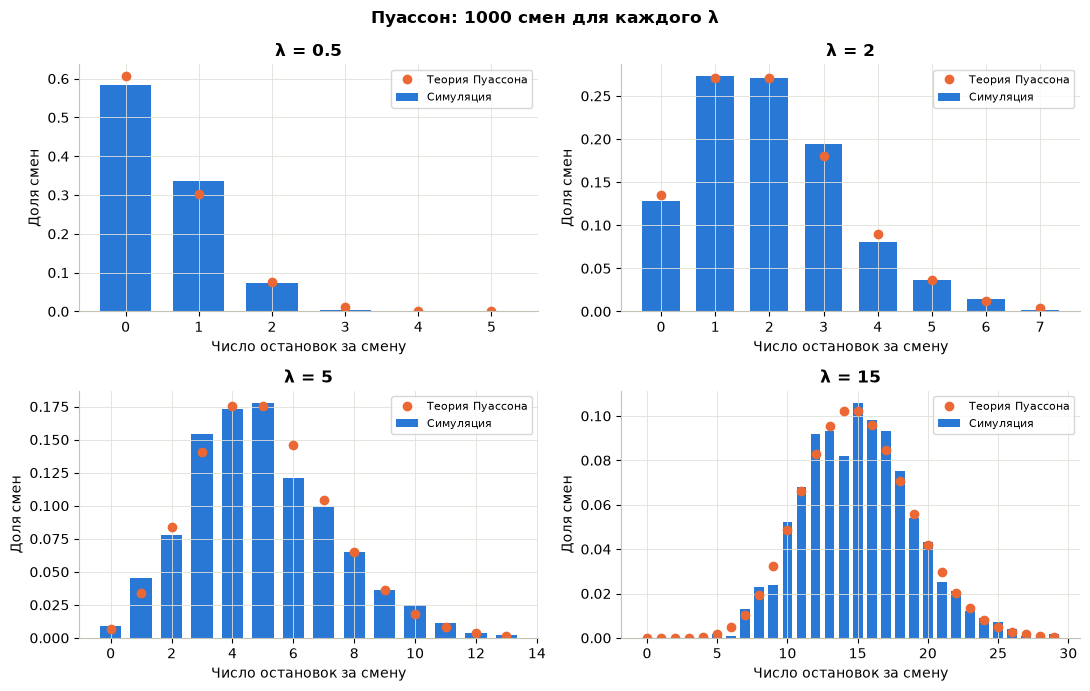

,среднее (симул.),дисперсия (симул.),дисперсия / среднее
λ,,,
0.5000,0.5040,0.4524,0.8977
2.0000,2.0060,1.9239,0.9591
5.0000,4.9530,5.4623,1.1028
15.0000,15.0540,15.0161,0.9975


In [12]:
N_SHIFTS = 1000
lambdas = [0.5, 2, 5, 15]
rows = []

fig, axes = plt.subplots(2, 2, figsize=(11, 7))
for ax, lam in zip(axes.ravel(), lambdas):
    x = rng.poisson(lam, size=N_SHIFTS)            # 1000 смен, в каждой — случайное число остановок
    kk = np.arange(0, x.max() + 1)
    obs = np.bincount(x, minlength=kk.size) / N_SHIFTS
    ax.bar(kk, obs, width=0.7, color=C_SIM, label="Симуляция")
    ax.plot(kk, stats.poisson.pmf(kk, lam), "o", color=C_THEO, ms=6, label="Теория Пуассона")
    ax.set_title(f"λ = {lam}")
    ax.set_xlabel("Число остановок за смену")
    ax.set_ylabel("Доля смен")
    ax.legend(fontsize=8)
    rows.append({"λ": lam, "среднее (симул.)": x.mean(), "дисперсия (симул.)": x.var(ddof=1),
                 "дисперсия / среднее": x.var(ddof=1) / x.mean()})
fig.suptitle("Пуассон: 1000 смен для каждого λ", fontweight="bold")
fig.tight_layout()
plt.show()

pd.DataFrame(rows).set_index("λ")

**Что я вижу.**
- При **λ = 0,5** больше половины смен вообще без остановок (P(0) = e^−0,5 ≈ 61 %).
- При росте λ форма из «столба у нуля» превращается в колокол — та же картина, что у биномиального.
- В таблице **дисперсия ≈ среднему** (отношение ≈ 1) для всех λ. Это «отпечаток пальца» Пуассона.

**Почему это важно.** Раз σ = √λ, то **разброс полностью задан средним**. Карта c поэтому строит границы из одного числа: c̄ ± 3√c̄ — она *не измеряет* разброс по данным, а *вычисляет* его из модели.
Это сильная сторона (нужно мало данных) и слабость: если в реальности дисперсия больше среднего (*сверхдисперсия / surdispersion* — например, разные смены, разные партии материала, дефекты «кучками»), границы карты c окажутся **слишком узкими** и будут сыпаться ложные тревоги. Именно поэтому Уилер советует проверять подсчёты картой XmR (блок 5).

**Биномиальное или Пуассон?** Подсказка: у биномиального есть фиксированное *n* и вопрос «да/нет» для каждой детали; у Пуассона нет «n попыток» — есть непрерывная «зона» (деталь, площадь, время), где события могут возникнуть в любом количестве.

---
## 3. НОРМАЛЬНОЕ РАСПРЕДЕЛЕНИЕ (*loi normale*) — диаметр детали

Допуск: **10 ± 0,03 мм** → НГД (LSL / *Ti, tolérance inférieure*) = 9,97; ВГД (USL / *Ts, tolérance supérieure*) = 10,03.
Процесс: **μ = 10,005**, **σ = 0,008** (слегка смещён вверх).

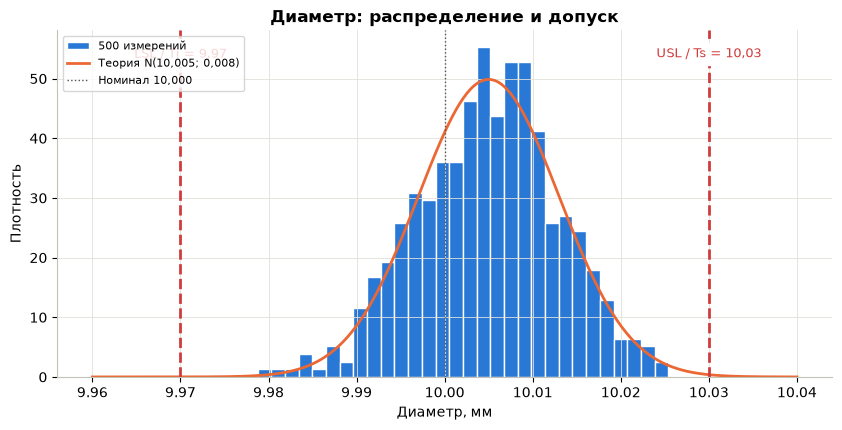

По истинным параметрам:  Cp = 1.25   Cpk = 1.04
   брак выше USL ≈ 889 ppm,  ниже LSL ≈ 6.1 ppm,  всего ≈ 895 ppm  (= 0.090 %)
По выборке 500 шт.:      Cp ≈ 1.24   Cpk ≈ 1.04   (среднее 10.0049, s = 0.0080)
Фактически вне допуска среди 500 деталей: 0 шт.


In [13]:
LSL, USL = 9.97, 10.03
MU, SIGMA = 10.005, 0.008
N_PARTS = 500

diam = rng.normal(MU, SIGMA, size=N_PARTS)          # 500 измеренных диаметров

# --- Индексы возможностей (capabilité) по ИСТИННЫМ μ и σ ---
Cp  = (USL - LSL) / (6 * SIGMA)                       # «влезает ли» разброс в допуск
Cpk = min(USL - MU, MU - LSL) / (3 * SIGMA)           # то же, но с учётом смещения центра

# Доля брака по нормальному закону (в ppm = частей на миллион)
ppm_hi = stats.norm.sf(USL, MU, SIGMA) * 1e6          # P(X > USL)
ppm_lo = stats.norm.cdf(LSL, MU, SIGMA) * 1e6         # P(X < LSL)

# --- Те же индексы по ВЫБОРКЕ из 500 деталей (так считают на практике) ---
m, s = diam.mean(), diam.std(ddof=1)
Cp_hat  = (USL - LSL) / (6 * s)
Cpk_hat = min(USL - m, m - LSL) / (3 * s)
n_out = ((diam > USL) | (diam < LSL)).sum()

fig, ax = plt.subplots()
ax.hist(diam, bins=30, density=True, color=C_SIM, edgecolor="white", label="500 измерений")
xx = np.linspace(9.96, 10.04, 400)
ax.plot(xx, stats.norm.pdf(xx, MU, SIGMA), color=C_THEO, lw=2, label="Теория N(10,005; 0,008)")
for v, name in [(LSL, "LSL / Ti = 9,97"), (USL, "USL / Ts = 10,03")]:
    ax.axvline(v, color=C_LIM, lw=2, ls="--")
    ax.text(v, ax.get_ylim()[1] * 0.95, name, color=C_LIM, ha="center", va="top",
            backgroundcolor="white", fontsize=9)
ax.axvline(10.0, color=C_CL, lw=1, ls=":", label="Номинал 10,000")
ax.set_xlabel("Диаметр, мм")
ax.set_ylabel("Плотность")
ax.set_title("Диаметр: распределение и допуск")
ax.legend(loc="upper left", fontsize=8)
plt.show()

print(f"По истинным параметрам:  Cp = {Cp:.2f}   Cpk = {Cpk:.2f}")
print(f"   брак выше USL ≈ {ppm_hi:,.0f} ppm,  ниже LSL ≈ {ppm_lo:,.1f} ppm,  всего ≈ {ppm_hi+ppm_lo:,.0f} ppm"
      f"  (= {(ppm_hi+ppm_lo)/1e4:.3f} %)")
print(f"По выборке 500 шт.:      Cp ≈ {Cp_hat:.2f}   Cpk ≈ {Cpk_hat:.2f}   (среднее {m:.4f}, s = {s:.4f})")
print(f"Фактически вне допуска среди 500 деталей: {n_out} шт.")

**Что я вижу.**
- **Cp = 1,25**: разброс (6σ = 0,048 мм) помещается в допуск (0,06 мм) с запасом.
- **Cpk ≈ 1,04**: из-за смещения центра на +0,005 мм до верхней границы остаётся всего ~3,1σ. Почти весь брак — **сверху**.
- Модель даёт **≈ 900 ppm (≈ 0,09 %)** брака. А среди 500 реальных деталей вне допуска, скорее всего, **0 или 1**.

**Почему это важно.**
1. Измерения позволяют **оценить** 900 ppm по 500 деталям — потому что мы видим *где* лежат детали внутри допуска, а не только «годна/негодна». Подсчётом брака на 500 деталях вы 900 ppm не увидите (ожидается 0,45 бракованной). Это главная мысль блока 6.
2. Здесь самое дешёвое улучшение — **отцентрировать** процесс (подвести μ к 10,000): Cpk станет равен Cp = 1,25, брак упадёт до ~180 ppm.
3. Осторожно с хвостами: ppm рассчитаны *по модели*. 900 ppm — это область, где реальное распределение может отличаться от нормального (Уилер на этом настаивает). Цифру ppm воспринимайте как порядок величины, а не как точное число.
4. По терминологии Pillet: Cp/Cpk считаются по краткосрочному σ (внутри подгрупп), а Pp/Ppk — по общему σ всех деталей. Здесь процесс стабилен «по построению», поэтому они совпадают; в реальном цехе обычно Ppk < Cpk.

---
## 4. СРАВНЕНИЕ: биномиальное ↔ Пуассон ↔ нормальное

### 4.1 Биномиальное B(50; 0,02) и Пуассон(λ = 1) почти совпадают

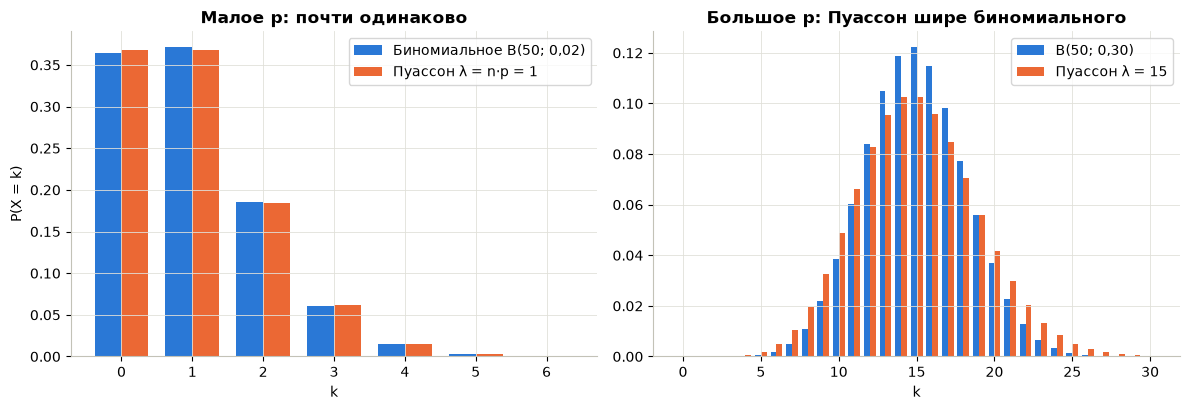

,Биномиальное,Пуассон,Разница
k,,,
0,0.3642,0.3679,-0.0037
1,0.3716,0.3679,0.0037
2,0.1858,0.1839,0.0019
3,0.0607,0.0613,-0.0006
4,0.0145,0.0153,-0.0008
5,0.0027,0.0031,-0.0003
6,0.0004,0.0005,-0.0001


In [14]:
k = np.arange(0, 7)
b = stats.binom.pmf(k, 50, 0.02)
po = stats.poisson.pmf(k, 1.0)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
w = 0.38
axes[0].bar(k - w/2, b, width=w, color=C_SIM, label="Биномиальное B(50; 0,02)")
axes[0].bar(k + w/2, po, width=w, color=C_THEO, label="Пуассон λ = n·p = 1")
axes[0].set_xticks(k)
axes[0].set_xlabel("k")
axes[0].set_ylabel("P(X = k)")
axes[0].set_title("Малое p: почти одинаково")
axes[0].legend()

# Для контраста: большое p — Пуассон уже плохо описывает биномиальное
k2 = np.arange(0, 31)
axes[1].bar(k2 - w/2, stats.binom.pmf(k2, 50, 0.30), width=w, color=C_SIM, label="B(50; 0,30)")
axes[1].bar(k2 + w/2, stats.poisson.pmf(k2, 15), width=w, color=C_THEO, label="Пуассон λ = 15")
axes[1].set_xlabel("k")
axes[1].set_title("Большое p: Пуассон шире биномиального")
axes[1].legend()
fig.tight_layout()
plt.show()

pd.DataFrame({"Биномиальное": b, "Пуассон": po, "Разница": b - po}, index=k).rename_axis("k")

**Что я вижу.** Слева столбики почти одинаковые: разница в вероятностях — порядка 0,01. Справа (p = 30 %) Пуассон заметно **шире**: его дисперсия λ = 15, а у биномиального n·p·(1−p) = 10,5.

**Почему.** Дисперсия биномиального n·p·(1−p) ≈ n·p, когда p мало (множитель 1−p ≈ 1). Значит, при **большом n и малом p** (примерно p < 0,1) биномиальное ≈ Пуассон с λ = n·p.
**Для контроля:** при малой доле брака неважно, какую из двух моделей взять для расчёта вероятностей. Но *выбор карты* (p или c) определяется не этим, а тем, **что вы считаете**: бракованные детали или дефекты.

### 4.2 Нормальное приближение: где работает, а где врёт

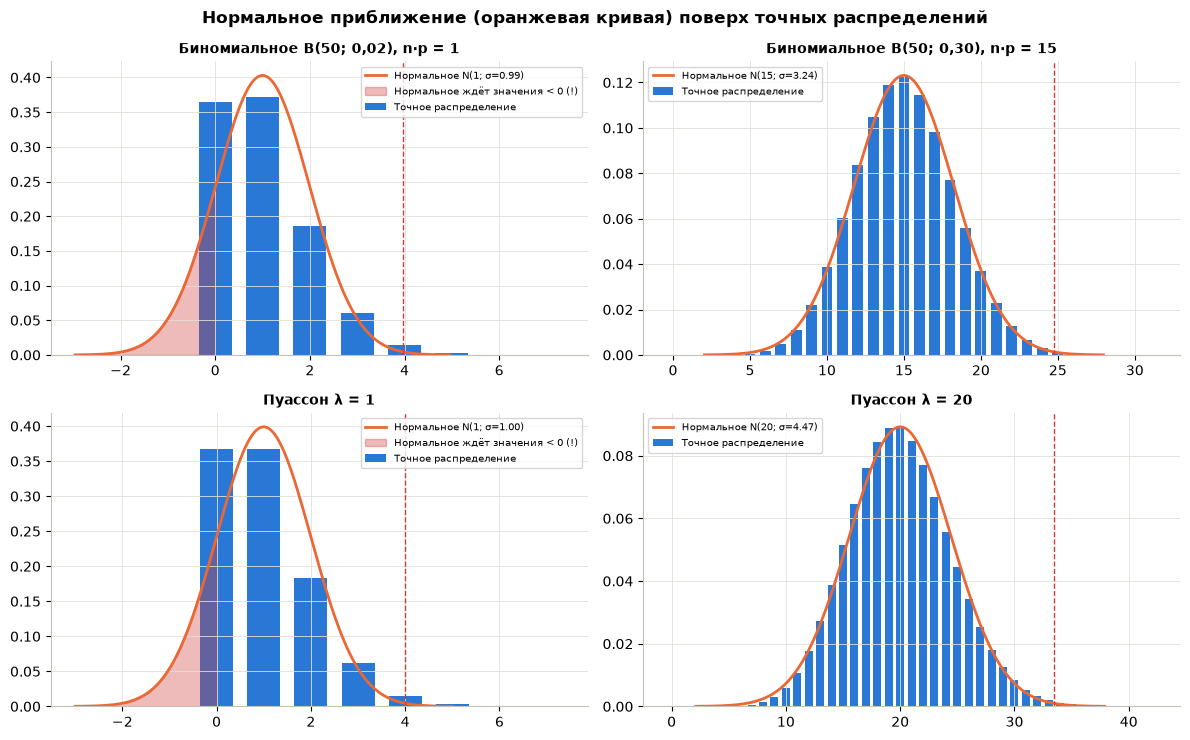

,UCL = μ+3σ,P(X > UCL) точно,P(X > UCL) по нормальному,P(X < 0) по нормальному
случай,,,,
"Биномиальное B(50; 0,02), n·p = 1",3.9698,0.0178,0.0013,0.0649
"Биномиальное B(50; 0,30), n·p = 15",24.7211,0.0024,0.0013,0.0000
Пуассон λ = 1,4.0000,0.0037,0.0013,0.0668
Пуассон λ = 20,33.4164,0.0027,0.0013,0.0000


In [15]:
cases = [
    ("Биномиальное B(50; 0,02), n·p = 1",   stats.binom(50, 0.02)),
    ("Биномиальное B(50; 0,30), n·p = 15",  stats.binom(50, 0.30)),
    ("Пуассон λ = 1",                        stats.poisson(1)),
    ("Пуассон λ = 20",                       stats.poisson(20)),
]

fig, axes = plt.subplots(2, 2, figsize=(12, 7.5))
rows = []
for ax, (name, dist) in zip(axes.ravel(), cases):
    mu, sd = dist.mean(), dist.std()
    lo, hi = int(max(0, mu - 4.5*sd)), int(mu + 4.5*sd) + 2
    kk = np.arange(lo, hi + 1)
    ax.bar(kk, dist.pmf(kk), width=0.7, color=C_SIM, label="Точное распределение")
    xx = np.linspace(mu - 4*sd, mu + 4*sd, 400)
    ax.plot(xx, stats.norm.pdf(xx, mu, sd), color=C_THEO, lw=2, label=f"Нормальное N({mu:g}; σ={sd:.2f})")
    neg = xx < 0
    if neg.any():   # закрашиваем «невозможную» область отрицательных значений
        ax.fill_between(xx[neg], stats.norm.pdf(xx[neg], mu, sd), color=C_LIM, alpha=0.35,
                        label="Нормальное ждёт значения < 0 (!)")
    ax.axvline(mu + 3*sd, color=C_LIM, ls="--", lw=1)
    ax.set_title(name, fontsize=10)
    ax.legend(fontsize=7.5)

    # Сравнение вероятностей, важных для карты: верхняя граница UCL = μ + 3σ
    ucl = mu + 3*sd
    rows.append({
        "случай": name,
        "UCL = μ+3σ": ucl,
        "P(X > UCL) точно": dist.sf(np.floor(ucl)),     # точная вероятность ложной тревоги сверху
        "P(X > UCL) по нормальному": stats.norm.sf(3),  # 0,00135 — то, что «обещает» ±3σ
        "P(X < 0) по нормальному": stats.norm.cdf(-0.5, mu, sd),  # с поправкой на непрерывность
    })
fig.suptitle("Нормальное приближение (оранжевая кривая) поверх точных распределений", fontweight="bold")
fig.tight_layout()
plt.show()

pd.DataFrame(rows).set_index("случай")

**Что я вижу.**
- **n·p = 15 и λ = 20**: колокол хорошо ложится на столбики. Нормальное приближение работает.
- **n·p = 1 и λ = 1**: кривая и столбики — разные формы. Колокол:
  1. **заходит в отрицательную область** (красная заливка) — «−1 бракованная деталь» не бывает;
  2. **симметричен**, а данные скошены вправо;
  3. недооценивает правый хвост: в таблице «P(X > UCL) точно» для B(50; 0,02) ≈ **1,8 %** — в **13 раз** больше обещанных 0,135 %; для Пуассона λ = 1 ≈ 0,37 % (почти в 3 раза больше).

  Честная оговорка: даже в «хороших» случаях (n·p = 15, λ = 20) точная вероятность ≈ 0,25 %, а не 0,135 % — дискретность и лёгкая асимметрия никуда не деваются. Но это ошибка «0,25 % вместо 0,13 %», а не «1,8 % вместо 0,13 %» — на практике приемлемо.

**Почему это важно.** Границы карт p и c — это «среднее ± 3σ», то есть нормальное приближение. При малых n·p / c̄:
- нижняя граница уходит в минус → её ставят 0, и карта **не может показать улучшение**;
- верхняя граница даёт **больше ложных тревог**, чем вы думаете.

Ориентиры: биномиальное ≈ нормальное при **n·p ≥ 5** (лучше и n·(1−p) ≥ 5); Пуассон ≈ нормальное при **λ ≥ 10–20**. Ниже этих значений — думайте о точных вероятностях или увеличивайте подгруппу.

---
## 5. КАРТЫ SPC (*cartes de contrôle*)

Общий сценарий для всех карт: **50 подгрупп**. Первые 25 — процесс стабилен (*базовый период*); с **подгруппы 26** процесс ухудшается (сдвиг).
Границы считаем **только по базовому периоду** (подгруппы 1–25) и продлеваем вперёд — так делают в цехе: сначала устанавливают границы по стабильному процессу, потом наблюдают новые точки. (Если считать по всем 50 точкам, сдвиг «раздует» границы и спрячет сам себя.)

Сигналы проверяем двумя правилами (из правил Western Electric, которые приводит и Уилер):
- **Правило 1:** точка за пределами контрольной границы (*point hors limites*) — ✕ красным;
- **Правило 4:** 8 точек подряд по одну сторону от центральной линии (*8 points consécutifs du même côté*) — ◆ зелёным.

In [16]:
N_SUB, SHIFT_AT = 50, 25        # 50 подгрупп, сдвиг начинается после 25-й (индекс 25 = подгруппа 26)
sub = np.arange(1, N_SUB + 1)   # номера подгрупп для оси X

def signals(x, cl, ucl, lcl):
    # Возвращает индексы точек с сигналом по правилу 1 и по правилу 4
    x = np.asarray(x)
    r1 = np.where((x > ucl) | (x < lcl))[0]
    side = np.sign(x - cl)
    r4 = [i for i in range(7, len(x)) if abs(side[i-7:i+1].sum()) == 8]
    return r1, np.array(r4, dtype=int)

def first_after_shift(r1, r4):
    # Номер подгруппы ПОСЛЕ сдвига, на которой карта впервые подала сигнал (1 = сразу первая же)
    hits = [i for i in np.concatenate([r1, r4]) if i >= SHIFT_AT]
    return (min(hits) - SHIFT_AT + 1) if hits else None

def plot_chart(ax, x, cl, ucl, lcl, title, ylabel):
    # Рисует контрольную карту, отмечает сигналы, возвращает «через сколько подгрупп пойман сдвиг»
    ax.plot(sub, x, "-o", color=C_SIM, ms=4, lw=1.2)
    ax.axhline(cl, color=C_CL, lw=1.2)
    ucl_arr = np.broadcast_to(ucl, x.shape); lcl_arr = np.broadcast_to(lcl, x.shape)
    ax.step(sub, ucl_arr, where="mid", color=C_LIM, ls="--", lw=1.2)
    if np.any(lcl_arr > 0):
        ax.step(sub, lcl_arr, where="mid", color=C_LIM, ls="--", lw=1.2)
    ax.axvspan(SHIFT_AT + 0.5, N_SUB + 0.5, color="#f0efec", zorder=0)
    ax.text(SHIFT_AT + 1, ax.get_ylim()[1], "после сдвига", va="top", fontsize=8, color=C_CL)
    r1, r4 = signals(x, cl, ucl_arr, lcl_arr)
    ax.plot(sub[r4], x[r4], "D", color=C_ALT, ms=8, mfc="none", mew=1.8, label="Правило 4 (8 подряд)")
    ax.plot(sub[r1], x[r1], "x", color=C_LIM, ms=10, mew=2.5, label="Правило 1 (вне границ)")
    ax.set_title(title); ax.set_ylabel(ylabel); ax.set_xlabel("Номер подгруппы")
    ax.legend(loc="upper left", fontsize=8)
    fs = first_after_shift(r1, r4)
    false_alarms = int((r1 < SHIFT_AT).sum())
    return fs, false_alarms

detect = {}   # сюда соберём «через сколько подгрупп после сдвига» для итоговой таблицы

### 5.1 Карта p (*carte p — proportion de défectueux*), n = 200

Каждый час берём 200 деталей и проверяем калибром «годен / не годен». Брак **2 % → 4 %** после сдвига.
Границы: p̄ ± 3·√(p̄(1−p̄)/n). Здесь n·p̄ = 4 — на грани правила «n·p ≥ 5», это реалистично.

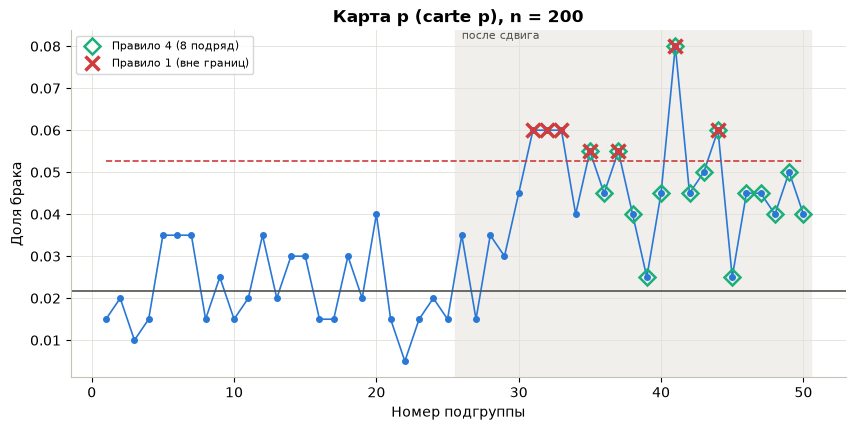

p̄ = 0.0218   UCL = 0.0528   LCL = 0.0000
Сдвиг замечен через 6 подгрупп(ы) после сдвига


In [17]:
n_p = 200
p_true = np.where(np.arange(N_SUB) < SHIFT_AT, 0.02, 0.04)   # 2 % до сдвига, 4 % после
np_counts = rng.binomial(n_p, p_true)                          # число бракованных в каждой подгруппе
p_frac = np_counts / n_p                                       # доля брака

p_bar = p_frac[:SHIFT_AT].mean()                               # центральная линия по базовому периоду
sigma_p = np.sqrt(p_bar * (1 - p_bar) / n_p)                   # σ из БИНОМИАЛЬНОЙ МОДЕЛИ
UCL_p, LCL_p = p_bar + 3*sigma_p, max(0.0, p_bar - 3*sigma_p)

fig, ax = plt.subplots()
detect["Карта p (n=200), брак 2→4 %"] = plot_chart(
    ax, p_frac, p_bar, UCL_p, LCL_p, "Карта p (carte p), n = 200", "Доля брака")
plt.show()
print(f"p̄ = {p_bar:.4f}   UCL = {UCL_p:.4f}   LCL = {LCL_p:.4f}")
print(f"Сдвиг замечен через {detect['Карта p (n=200), брак 2→4 %'][0]} подгрупп(ы) после сдвига")

**Что я вижу.** До сдвига точки гуляют вокруг p̄, нижней границы нет (p̄ − 3σ < 0 → 0). После сдвига точки в среднем выше, но **даже удвоение брака** выводит за UCL лишь часть точек — вероятность выхода для одной подгруппы около 30 %, поэтому сигнал приходит через несколько подгрупп, и правило «8 подряд выше центра» — хорошая подстраховка.

**Почему это важно.** Даже при n = 200 карта p — довольно «грубый» инструмент: брак удвоился, а сигнал приходит не сразу. Детали проверены, но информация о том, *насколько близко к границе допуска* они были, потеряна.

### 5.2 Карта c (*carte c — nombre de défauts*)

Каждый час берём одну деталь и считаем царапины/раковины на ней. Среднее **3 → 6** дефектов.
Границы: c̄ ± 3·√c̄ (из Пуассона: дисперсия = среднему).

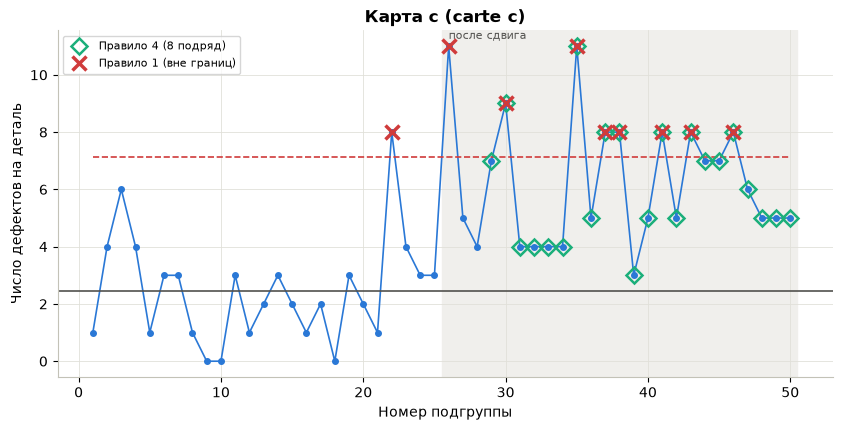

c̄ = 2.44   UCL = 7.13   LCL = 0.00
Сдвиг замечен через 1 подгрупп(ы) после сдвига


In [18]:
lam_true = np.where(np.arange(N_SUB) < SHIFT_AT, 3.0, 6.0)
c_counts = rng.poisson(lam_true)

c_bar = c_counts[:SHIFT_AT].mean()
UCL_c, LCL_c = c_bar + 3*np.sqrt(c_bar), max(0.0, c_bar - 3*np.sqrt(c_bar))

fig, ax = plt.subplots()
detect["Карта c, дефекты 3→6 на деталь"] = plot_chart(
    ax, c_counts.astype(float), c_bar, UCL_c, LCL_c, "Карта c (carte c)", "Число дефектов на деталь")
plt.show()
print(f"c̄ = {c_bar:.2f}   UCL = {UCL_c:.2f}   LCL = {LCL_c:.2f}")
print(f"Сдвиг замечен через {detect['Карта c, дефекты 3→6 на деталь'][0]} подгрупп(ы) после сдвига")

**Что я вижу.** Удвоение числа дефектов видно «на глаз»; одиночная точка после сдвига выходит за UCL примерно с вероятностью 15–35 % (зависит от того, где легла UCL), так что сигнал может прийти сразу, а может через несколько подгрупп. Обратите внимание: и **до** сдвига возможна ложная тревога — при c̄ ≈ 3 правый хвост Пуассона толще, чем обещает «±3σ» (блок 4). Нижней границы нет (c̄ − 3√c̄ < 0) — значит, **улучшение карта c показать не сможет** по правилу 1.

### 5.3 Карта X̄-R (*carte moyenne-étendue*), подгруппы по 5

Измеряем диаметр 5 деталей каждый час. Процесс из блока 3 (μ = 10,005, σ = 0,008). После сдвига среднее уходит на **+1σ = +0,008 мм** (например, износ инструмента).
Границы по классическим константам для n = 5: **A2 = 0,577, D3 = 0, D4 = 2,114**.

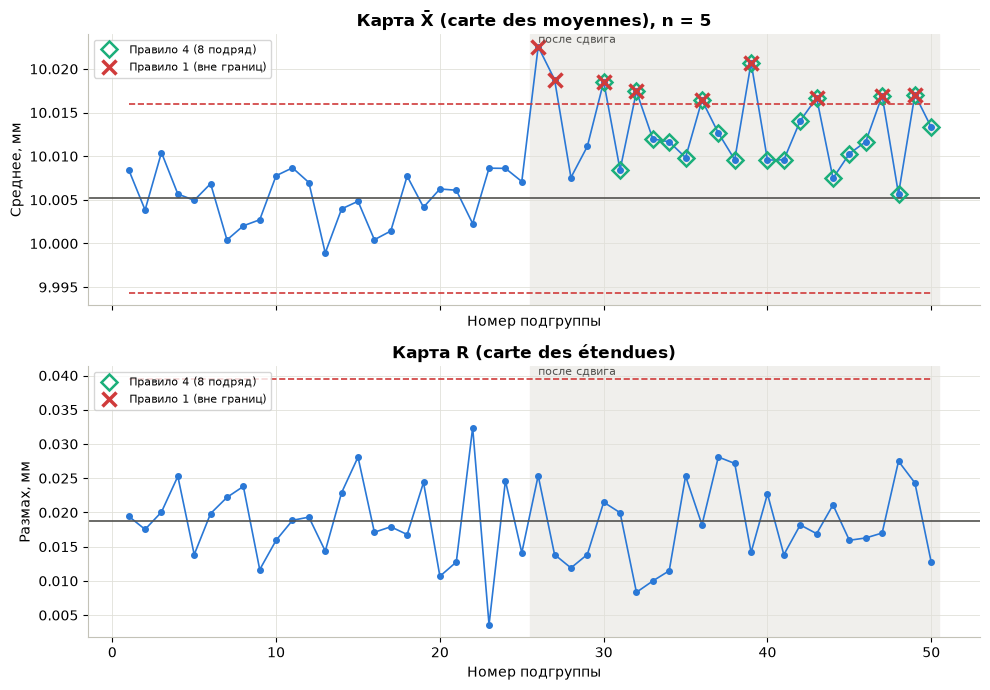

X̄̄ = 10.0052  UCL = 10.0160  LCL = 9.9944  |  R̄ = 0.0187  UCL_R = 0.0395
σ по R̄/d2 = 0.0080  (истинное σ = 0.008)
Сдвиг замечен через 1 подгрупп(ы) после сдвига


In [19]:
A2, D3, D4 = 0.577, 0.0, 2.114          # константы для подгрупп по 5 (есть в любом учебнике, и у Pillet)
mu_true = np.where(np.arange(N_SUB) < SHIFT_AT, MU, MU + SIGMA)
X = rng.normal(mu_true[:, None], SIGMA, size=(N_SUB, 5))   # матрица 50 × 5: каждая строка — подгруппа
xbar = X.mean(axis=1)
R = X.max(axis=1) - X.min(axis=1)

xbarbar, R_bar = xbar[:SHIFT_AT].mean(), R[:SHIFT_AT].mean()
UCL_x, LCL_x = xbarbar + A2*R_bar, xbarbar - A2*R_bar
UCL_R, LCL_R = D4*R_bar, D3*R_bar

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(10, 7), sharex=True)
detect["Карта X̄ (n=5), сдвиг +1σ"] = plot_chart(ax1, xbar, xbarbar, UCL_x, LCL_x,
                                                "Карта X̄ (carte des moyennes), n = 5", "Среднее, мм")
plot_chart(ax2, R, R_bar, UCL_R, LCL_R, "Карта R (carte des étendues)", "Размах, мм")
fig.tight_layout()
plt.show()
print(f"X̄̄ = {xbarbar:.4f}  UCL = {UCL_x:.4f}  LCL = {LCL_x:.4f}  |  R̄ = {R_bar:.4f}  UCL_R = {UCL_R:.4f}")
print(f"σ по R̄/d2 = {R_bar/2.326:.4f}  (истинное σ = {SIGMA})")
print(f"Сдвиг замечен через {detect['Карта X̄ (n=5), сдвиг +1σ'][0]} подгрупп(ы) после сдвига")

**Что я вижу.** На карте X̄ точки после сдвига явно «переезжают» вверх, правило 8 подряд срабатывает почти гарантированно, выходы за UCL — частые. Карта R не меняется: сдвиг *среднего* не меняет *разброс* внутри подгруппы — так карты и разделяют две причины (смещение настройки vs. рост рассеяния).

Обратите внимание на масштаб: сдвиг на 1σ сам по себе поднимает брак всего с ~0,09 % до ~1,7 %. Карта X̄ видит это по **5 деталям** в час; карта по атрибутам с 5 деталями не увидела бы ничего (см. блок 6).

### 5.4 Карта XmR на тех же данных, что карта p (*carte des valeurs individuelles et étendues mobiles*, *carte I-MR*)

Берём те же 50 долей брака p_i и обращаемся с ними **как с обычными измерениями**. Никакой биномиальной модели — разброс измеряем **прямо по данным**, через скользящие размахи mR = |p_i − p_(i−1)|.
Границы: X̄ ± **2,66**·mR̄; для mR: UCL = **3,268**·mR̄.

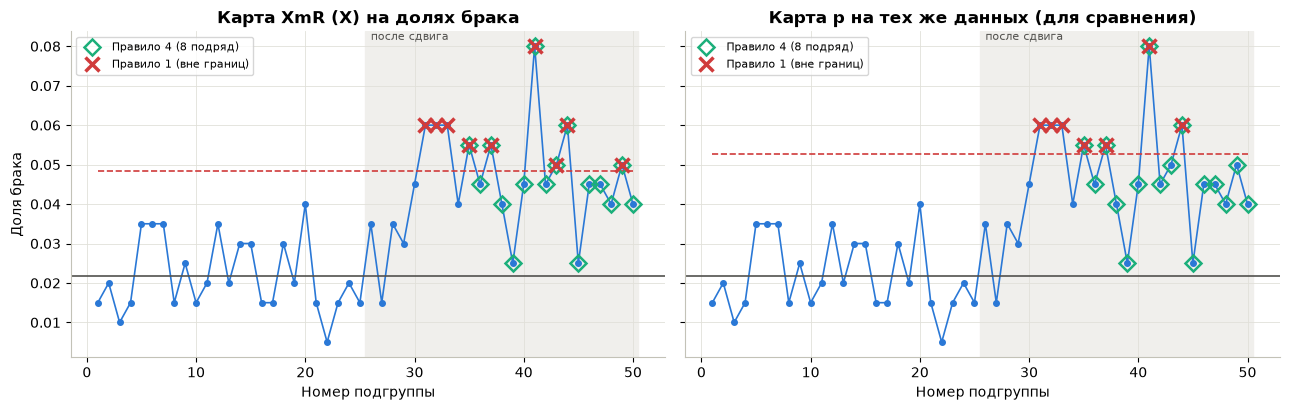

,Центр,UCL,LCL,"σ, использованная для границ"
Карта p (σ из биномиальной модели),0.0218,0.0528,0.0000,0.0103
"Карта XmR (σ по данным: mR̄/1,128)",0.0218,0.0484,0.0000,0.0089


In [20]:
def xmr_limits(x_base):
    # Границы XmR по базовому периоду
    mr = np.abs(np.diff(x_base))
    xb, mrb = x_base.mean(), mr.mean()
    return xb, xb + 2.66*mrb, xb - 2.66*mrb, mrb

xb, UCL_i, LCL_i, mR_bar = xmr_limits(p_frac[:SHIFT_AT])
mR = np.r_[np.nan, np.abs(np.diff(p_frac))]

fig, axes = plt.subplots(1, 2, figsize=(13, 4.2), sharey=True)
detect["Карта XmR на тех же долях брака"] = plot_chart(
    axes[0], p_frac, xb, UCL_i, max(0.0, LCL_i), "Карта XmR (X) на долях брака", "Доля брака")
plot_chart(axes[1], p_frac, p_bar, UCL_p, LCL_p, "Карта p на тех же данных (для сравнения)", "")
fig.tight_layout()
plt.show()

pd.DataFrame({"Центр": [p_bar, xb], "UCL": [UCL_p, UCL_i], "LCL": [LCL_p, max(0.0, LCL_i)],
              "σ, использованная для границ": [sigma_p, mR_bar/1.128]},
             index=["Карта p (σ из биномиальной модели)", "Карта XmR (σ по данным: mR̄/1,128)"])

**Что я вижу.** Границы двух карт **близки** (обычно расходятся на 5–20 % — XmR оценивает σ всего по 24 скользящим размахам, поэтому её границы сами немного «шумят»). Это ожидаемо: данные *действительно* биномиальные, и XmR, ничего не зная о модели, «намерила» примерно тот же разброс. Сдвиг обе ловят сопоставимо.

**Тогда зачем Уилер рекомендует XmR?** Потому что в реальном цехе данные о браке **редко бывают чисто биномиальными**: доля брака плавает от партии материала к партии, от смены к смене. Карта p этого не знает и берёт σ из формулы — границы получаются **слишком узкими**. Покажу это на примере.

### 5.5 Бонус: реалистичный случай — доля брака «плавает» от подгруппы к подгруппе (сверхдисперсия)

Процесс **стабилен** (ничего не менялось, сдвига нет!), но истинная доля брака в каждой подгруппе случайно колеблется вокруг 2 % (бета-распределение, стандартное отклонение ≈ 1,5 %) — например, разные прутки материала или разные настройщики.

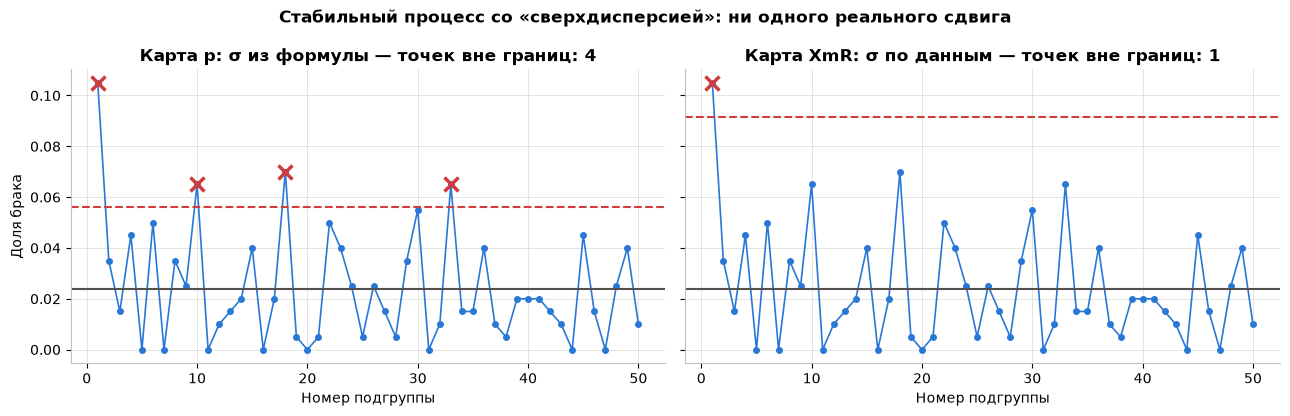

Дисперсия наблюдаемых долей / дисперсия по биномиальной модели = 4.3  (для чистого биномиального ≈ 1)


In [21]:
# Истинная доля брака каждой подгруппы ~ Beta со средним 2 % и σ ≈ 1,5 %
# (параметры подобраны: a/(a+b) = 0,02;  a+b+1 = 0,02·0,98 / 0,015²)
a, b_ = 1.72, 84.4
p_wobble = rng.beta(a, b_, size=N_SUB)
od_frac = rng.binomial(n_p, p_wobble) / n_p        # наблюдаемая доля брака, n = 200, БЕЗ сдвига

pb2 = od_frac.mean()                                # здесь границы по всем 50 (сдвига нет)
s2 = np.sqrt(pb2*(1-pb2)/n_p)
xb2, U2, L2, mrb2 = xmr_limits(od_frac)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.2), sharey=True)
for ax, (cl, u, l, ttl) in zip(axes, [(pb2, pb2+3*s2, max(0, pb2-3*s2), "Карта p: σ из формулы"),
                                       (xb2, U2, max(0, L2), "Карта XmR: σ по данным")]):
    ax.plot(sub, od_frac, "-o", color=C_SIM, ms=4, lw=1.2)
    ax.axhline(cl, color=C_CL)
    ax.axhline(u, color=C_LIM, ls="--")
    if l > 0: ax.axhline(l, color=C_LIM, ls="--")
    out = (od_frac > u) | (od_frac < l)
    ax.plot(sub[out], od_frac[out], "x", color=C_LIM, ms=10, mew=2.5)
    ax.set_title(f"{ttl} — точек вне границ: {out.sum()}")
    ax.set_xlabel("Номер подгруппы")
axes[0].set_ylabel("Доля брака")
fig.suptitle("Стабильный процесс со «сверхдисперсией»: ни одного реального сдвига", fontweight="bold")
fig.tight_layout()
plt.show()
print(f"Дисперсия наблюдаемых долей / дисперсия по биномиальной модели = {od_frac.var(ddof=1)/s2**2:.1f}  (для чистого биномиального ≈ 1)")

**Что я вижу.** Процесс ничем не нарушен, но карта p выдаёт **ложные тревоги** — несколько точек «вне границ». Карта XmR на тех же точках спокойна (или почти): она измерила реальный разброс — по дисперсии в несколько раз больше биномиального (точное отношение напечатано под графиком), поэтому её границы заметно шире.

**Почему это важно (аргумент Уилера).** Карта p/c *предполагает* модель; XmR *проверяет данные*. Если модель верна — обе дают похожие границы (5.4), и XmR почти ничего не теряет. Если модель неверна — карта p кричит «волк!», люди перестают ей верить. Практический совет: стройте **обе** карты на своих данных о браке. Если границы сильно разные — биномиальная/пуассоновская модель к вашему процессу не подходит, доверяйте XmR.

Оговорка (не упрощаем до неправды): XmR корректна для долей, когда размер подгрупп n **примерно одинаков**. Если n сильно меняется от подгруппы к подгруппе, карта p (с переменными границами) или карта Laney p′ обрабатывают это корректнее.

### 5.6 Кто поймал сдвиг быстрее

In [22]:
pd.DataFrame(
    {"Сигнал через N подгрупп после сдвига": {k_: v[0] for k_, v in detect.items()},
     "Ложных тревог по правилу 1 до сдвига": {k_: v[1] for k_, v in detect.items()}}
)

,Сигнал через N подгрупп после сдвига,Ложных тревог по правилу 1 до сдвига
"Карта p (n=200), брак 2→4 %",6,0
"Карта c, дефекты 3→6 на деталь",1,1
"Карта X̄ (n=5), сдвиг +1σ",1,0
Карта XmR на тех же долях брака,6,0


**Как читать.** Это **одна** случайная реализация, поэтому цифры — иллюстрация, а не закон (поменяйте `seed` в ячейке 0 и запустите заново — порядок может меняться). Сами сдвиги тоже разные (удвоение брака, удвоение дефектов, +1σ размера), поэтому сравнивать карты *разных* типов строка к строке нельзя.
Корректное сравнение «атрибуты vs. измерения» на **одном и том же** ухудшении процесса — в блоке 6, где считаем средние значения по тысячам повторений.

---
## 6. «СЛЕПОТА» КОНТРОЛЯ ПО АТРИБУТАМ

### 6.1 Брак 0,1 %, выборки по 50 деталей: как часто брак вообще не находится?

Выборок без единого брака: симуляция 95.2%   теория 0,999^50 = 95.1%
В среднем первый брак находим через 20.5 выборок = 1025 проверенных деталей

Карта p: p̄ = 0.001, UCL = 0.0144, а ОДНА бракованная деталь из 50 = 0.020  > UCL!
→ любой найденный брак = «сигнал». Вероятность ложной тревоги на выборку = 4.9% вместо обещанных 0,135 %  (в 36 раз больше)


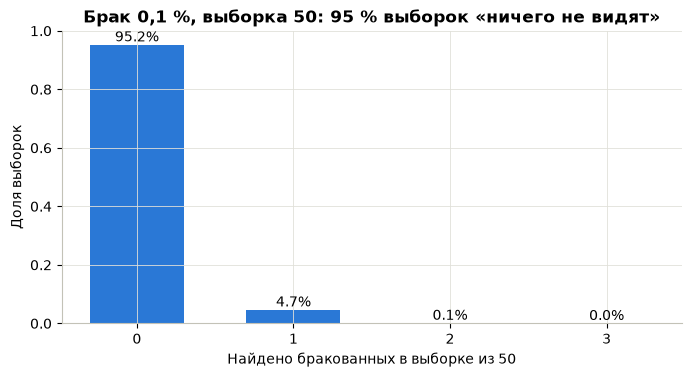

In [23]:
p_low, n_s = 0.001, 50
N_SAMPLES = 10_000
found = rng.binomial(n_s, p_low, size=N_SAMPLES)

P0_th = stats.binom.pmf(0, n_s, p_low)
print(f"Выборок без единого брака: симуляция {np.mean(found == 0):.1%}   теория 0,999^50 = {P0_th:.1%}")
print(f"В среднем первый брак находим через {1/(1-P0_th):.1f} выборок = {n_s/(1-P0_th):.0f} проверенных деталей")

# Что будет с классической картой p при таких параметрах?
sig = np.sqrt(p_low*(1-p_low)/n_s)
ucl_low = p_low + 3*sig
print(f"\nКарта p: p̄ = {p_low:.3f}, UCL = {ucl_low:.4f}, а ОДНА бракованная деталь из 50 = {1/n_s:.3f}  > UCL!")
print(f"→ любой найденный брак = «сигнал». Вероятность ложной тревоги на выборку = {1-P0_th:.1%}"
      f" вместо обещанных 0,135 %  (в {(1-P0_th)/0.00135:.0f} раз больше)")

fig, ax = plt.subplots(figsize=(8, 3.8))
kk = np.arange(0, 4)
ax.bar(kk, np.bincount(found, minlength=4)[:4] / N_SAMPLES, color=C_SIM, width=0.6)
for k_, v in zip(kk, np.bincount(found, minlength=4)[:4] / N_SAMPLES):
    ax.text(k_, v, f"{v:.1%}", ha="center", va="bottom")
ax.set_xticks(kk)
ax.set_xlabel("Найдено бракованных в выборке из 50")
ax.set_ylabel("Доля выборок")
ax.set_title("Брак 0,1 %, выборка 50: 95 % выборок «ничего не видят»")
plt.show()

**Что я вижу.** В **~95 %** выборок брака нет вообще. Первый бракованный в среднем находится лишь через ~20 выборок (~1000 деталей). А классическая формула карты p ломается: её UCL ниже, чем одна деталь из 50, — значит, каждая найденная бракованная деталь объявляется «сигналом», хотя процесс не менялся.

**Почему это важно.** При хорошем процессе (брак ≤ 0,1 %) выборочный контроль атрибутов на десятках деталей почти не несёт информации: «0 брака» — это нормальный ответ и для 0,1 %, и для 0,5 %. Вывод «брака нет — значит всё хорошо» на таких выборках **статистически пустой**.

### 6.2 Одно и то же ухудшение: карта p (50 деталей калибром) vs. карта X̄ (5 деталей измерено)

Берём процесс из блока 3 (диаметр, μ = 10,005, σ = 0,008, допуск 10 ± 0,03): брак ≈ **0,09 % ≈ 0,1 %**.
Ухудшение: среднее уезжает вверх на Δ (износ инструмента). Сравниваем:
- **Карта p, n = 50** (контроль калибром *entre / n'entre pas*). Две версии: «по формуле» (сигнал при ≥ 1 браке — как получилось выше) и «честная» с **вероятностной границей**: сигнал при ≥ 2 браках — тогда ложные тревоги ≈ 0,1 %, сопоставимо с ±3σ;
- **Карта X̄, n = 5** (те же детали, но 5 из них измерены), правило 1.

Мерило — **POM / ARL** (*Période Opérationnelle Moyenne* у Pillet, *Average Run Length*): сколько выборок в среднем проходит до сигнала. До сдвига хотим большой ARL (мало ложных тревог), после — маленький (быстрое обнаружение).

In [24]:
def p_defect(mu):
    # Доля брака при среднем mu (нормальный закон, обе границы допуска)
    return stats.norm.sf(USL, mu, SIGMA) + stats.norm.cdf(LSL, mu, SIGMA)

def arl_pchart(mu, n=50, k_signal=1):
    # ARL карты p: сигнал, если в выборке из n найдено ≥ k_signal бракованных
    prob = stats.binom.sf(k_signal - 1, n, p_defect(mu))
    return 1 / prob

def arl_xbar(mu, n=5):
    # ARL карты X̄ (правило 1) с границами MU ± 3σ/√n, установленными по исходному процессу
    se = SIGMA / np.sqrt(n)
    prob = stats.norm.sf(MU + 3*se, mu, se) + stats.norm.cdf(MU - 3*se, mu, se)
    return 1 / prob

shifts = np.array([0, 0.25, 0.5, 0.75, 1.0, 1.5, 2.0])   # сдвиг в долях σ
tab = pd.DataFrame({
    "Сдвиг (σ)": shifts,
    "Брак, %": [100*p_defect(MU + d*SIGMA) for d in shifts],
    "ARL карта p (≥1 брак)": [arl_pchart(MU + d*SIGMA, k_signal=1) for d in shifts],
    "ARL карта p (≥2 брака)": [arl_pchart(MU + d*SIGMA, k_signal=2) for d in shifts],
    "ARL карта X̄ n=5": [arl_xbar(MU + d*SIGMA) for d in shifts],
}).set_index("Сдвиг (σ)")
# Сколько деталей придётся проверить до сигнала = ARL × размер выборки
tab["Деталей до сигнала: p (≥2)"] = tab["ARL карта p (≥2 брака)"] * 50
tab["Деталей до сигнала: X̄"] = tab["ARL карта X̄ n=5"] * 5
tab.style.format("{:,.1f}").format("{:.3f}", subset=["Брак, %"])

,"Брак, %",ARL карта p (≥1 брак),ARL карта p (≥2 брака),ARL карта X̄ n=5,Деталей до сигнала: p (≥2),Деталей до сигнала: X̄
Сдвиг (σ),,,,,,
0.000000,0.090,22.8,"1,048.4",370.4,"52,422.2","1,852.0"
0.250000,0.202,10.4,213.0,133.2,"10,648.2",665.8
0.500000,0.433,5.1,49.9,33.4,"2,494.8",167.0
0.750000,0.877,2.8,14.0,10.8,699.1,53.8
1.000000,1.679,1.8,4.9,4.5,243.9,22.5
1.500000,5.208,1.1,1.3,1.6,67.4,7.8
2.000000,13.029,1.0,1.0,1.1,50.4,5.4


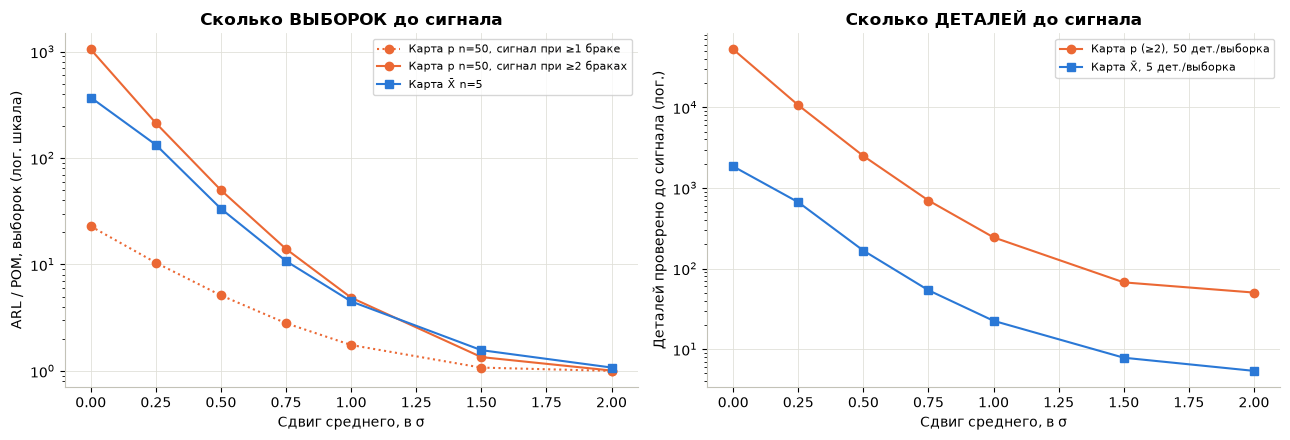

In [25]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].semilogy(shifts, tab["ARL карта p (≥1 брак)"], "o", color=C_THEO, ls=":", label="Карта p n=50, сигнал при ≥1 браке")
axes[0].semilogy(shifts, tab["ARL карта p (≥2 брака)"], "-o", color=C_THEO, label="Карта p n=50, сигнал при ≥2 браках")
axes[0].semilogy(shifts, tab["ARL карта X̄ n=5"], "-s", color=C_SIM, label="Карта X̄ n=5")
axes[0].set_xlabel("Сдвиг среднего, в σ")
axes[0].set_ylabel("ARL / POM, выборок (лог. шкала)")
axes[0].set_title("Сколько ВЫБОРОК до сигнала")
axes[0].legend(fontsize=8)

axes[1].semilogy(shifts, tab["Деталей до сигнала: p (≥2)"], "-o", color=C_THEO, label="Карта p (≥2), 50 дет./выборка")
axes[1].semilogy(shifts, tab["Деталей до сигнала: X̄"], "-s", color=C_SIM, label="Карта X̄, 5 дет./выборка")
axes[1].set_xlabel("Сдвиг среднего, в σ")
axes[1].set_ylabel("Деталей проверено до сигнала (лог.)")
axes[1].set_title("Сколько ДЕТАЛЕЙ до сигнала")
axes[1].legend(fontsize=8)
fig.tight_layout()
plt.show()

In [26]:
# Проверка формул симуляцией: сдвиг +1σ, 20 000 повторений «ждём первого сигнала»
REPS, d = 20_000, 1.0
mu1 = MU + d*SIGMA

# Карта p (≥2): число выборок до первого сигнала — геометрическое распределение
prob_p = stats.binom.sf(1, 50, p_defect(mu1))
run_p = rng.geometric(prob_p, size=REPS)

# Карта X̄: честно генерируем подгруппы по 5 и ждём первого выхода за границу
se = SIGMA/np.sqrt(5)
run_x = np.empty(REPS, dtype=int)
for r in range(REPS):
    i = 0
    while True:
        i += 1
        m5 = rng.normal(mu1, SIGMA, 5).mean()
        if m5 > MU + 3*se or m5 < MU - 3*se:
            break
    run_x[r] = i

print(f"Сдвиг +1σ (брак {p_defect(MU):.2%} → {p_defect(mu1):.2%}):")
print(f"  Карта p (n=50, ≥2): средний ARL = {run_p.mean():.1f} выборок  (формула {arl_pchart(mu1, k_signal=2):.1f})"
      f"  → {50*run_p.mean():.0f} деталей")
print(f"  Карта X̄ (n=5):     средний ARL = {run_x.mean():.1f} выборок  (формула {arl_xbar(mu1):.1f})"
      f"  → {5*run_x.mean():.0f} деталей")

Сдвиг +1σ (брак 0.09% → 1.68%):
  Карта p (n=50, ≥2): средний ARL = 4.9 выборок  (формула 4.9)  → 246 деталей
  Карта X̄ (n=5):     средний ARL = 4.5 выборок  (формула 4.5)  → 22 деталей


**Что я вижу.**
- **Без сдвига** (строка 0): карта p «по формуле» (≥ 1 брак) даёт ложную тревогу в среднем каждые ~23 выборки — ею невозможно пользоваться (поэтому на левом графике её пунктирная кривая «быстрее всех» — она просто всё время кричит). «Честная» версия (≥ 2, ARL₀ ≈ 1000) и карта X̄ (ARL₀ ≈ 370) спокойны. Их ложные тревоги не одинаковы — дискретная карта p не умеет попасть ровно в 0,27 %, — но порядок один.
- **Сдвиг +1σ** (брак вырос в ~20 раз!): карта X̄ замечает его в среднем за **~4–5 выборок по 5 деталей ≈ 20–25 деталей**. Честная карта p — тоже за ~5 выборок, но **по 50 деталей ≈ 250 деталей**. То есть **в 10 раз больше контроля ради того же результата**.
- **Малые сдвиги** (0,25–0,5σ): обе карты медленные, но в пересчёте на проверенные детали X̄ всё равно в разы эффективнее.
- Симуляция подтверждает формулы ARL.

**Почему это важно.** Калибр «годен/не годен» выбрасывает информацию: деталь 10,029 и деталь 10,001 для него одинаковые — «годна». Измерение видит, что процесс **подползает** к границе, *до того* как появился брак. При малой доле брака атрибутивный контроль либо слеп (мало деталей), либо дорог (много деталей), либо шумит (неправильные границы). Отсюда практическое правило: **если характеристику можно измерить — измеряйте и стройте карту по переменным**; атрибуты оставьте для того, что измерить нельзя (внешний вид, наличие операции, функциональный тест).

---
## 7. ИТОГ

### 7.1 Шпаргалка

In [27]:
summary = pd.DataFrame([
    ["Годна / не годна (калибр, визуальный осмотр «да/нет»), n постоянно",
     "Données par attributs — défectueux", "Биномиальное", "Карта np или p (carte np / p)",
     "Нельзя измерить; n·p̄ ≥ 5 (иначе увеличить n); проверять XmR на сверхдисперсию"],
    ["Годна / не годна, n меняется", "Données par attributs — défectueux", "Биномиальное",
     "Карта p с переменными границами (carte p)", "Разные размеры партий; при больших n — карта Laney p′"],
    ["Число дефектов на деталь / на единицу (одинаковая «зона»)", "Données par attributs — défauts",
     "Пуассон", "Карта c (carte c)", "c̄ ≥ ~5–10 для разумных границ; дисперсия ≈ среднему"],
    ["Число дефектов на единицу, размер «зоны» меняется (м², длина, время)", "Données par attributs — défauts",
     "Пуассон", "Карта u (carte u)", "Дефекты на м², на 100 деталей, на час работы"],
    ["Измерения, подгруппы 2–10 (размер, шероховатость, момент)", "Données par variables (mesures)",
     "Нормальное (часто приблизительно)", "Карта X̄-R / X̄-s (carte moyenne-étendue)",
     "Основной инструмент в механообработке; лучшая чувствительность на деталь"],
    ["Одно значение за раз (редкие замеры, партия = 1 значение, или подсчёты)",
     "Variables ИЛИ attributs", "Любое (карта не опирается на модель)",
     "Карта XmR / I-MR (carte valeurs individuelles)",
     "Медленные процессы, лабораторные результаты, подсчёты со сверхдисперсией (Уилер)"],
], columns=["Тип данных", "Français", "Распределение", "Карта SPC", "Когда использовать"])
summary.style.set_properties(**{"text-align": "left", "white-space": "pre-wrap"}).hide(axis="index")

Тип данных,Français,Распределение,Карта SPC,Когда использовать
"Годна / не годна (калибр, визуальный осмотр «да/нет»), n постоянно",Données par attributs — défectueux,Биномиальное,Карта np или p (carte np / p),Нельзя измерить; n·p̄ ≥ 5 (иначе увеличить n); проверять XmR на сверхдисперсию
"Годна / не годна, n меняется",Données par attributs — défectueux,Биномиальное,Карта p с переменными границами (carte p),Разные размеры партий; при больших n — карта Laney p′
Число дефектов на деталь / на единицу (одинаковая «зона»),Données par attributs — défauts,Пуассон,Карта c (carte c),c̄ ≥ ~5–10 для разумных границ; дисперсия ≈ среднему
"Число дефектов на единицу, размер «зоны» меняется (м², длина, время)",Données par attributs — défauts,Пуассон,Карта u (carte u),"Дефекты на м², на 100 деталей, на час работы"
"Измерения, подгруппы 2–10 (размер, шероховатость, момент)",Données par variables (mesures),Нормальное (часто приблизительно),Карта X̄-R / X̄-s (carte moyenne-étendue),Основной инструмент в механообработке; лучшая чувствительность на деталь
"Одно значение за раз (редкие замеры, партия = 1 значение, или подсчёты)",Variables ИЛИ attributs,Любое (карта не опирается на модель),Карта XmR / I-MR (carte valeurs individuelles),"Медленные процессы, лабораторные результаты, подсчёты со сверхдисперсией (Уилер)"


**Выводы:**
1. **«Деталь» или «дефект»?** Если вы классифицируете деталь (годна/нет) — биномиальное. Если считаете события на детали — Пуассон. Одна деталь может дать *1 бракованную* и *3 дефекта* одновременно.
2. **Малые числа — не колокол.** При n·p < 5 или c̄ < ~10 формулы «±3σ» дают нижнюю границу 0 и лишние ложные тревоги.
3. **Измерение сильнее подсчёта.** При малой доле брака атрибуты почти слепы; карта по переменным ловит дрейф до появления брака с гораздо меньшим числом деталей.

### 7.2 Задачи для самопроверки

Сначала решите сами, потом раскройте ответ. Для расчётов можно использовать ячейку ниже.

**Задача 1.** На корпусе нашли 3 царапины. Вы ведёте учёт числа царапин на каждом корпусе. Какое распределение и какая карта? А если вас интересует только «корпус годен / с царапинами»?

<details><summary>Ответ</summary>

Число царапин на детали — **Пуассон** (нет фиксированного «n попыток», царапин может быть сколько угодно) → **карта c** (или u, если площадь/количество деталей в единице контроля меняется).
Если вы классифицируете корпус как «годен / не годен» — это **биномиальное** (корпус с 3 царапинами = 1 бракованная деталь) → **карта p / np**. Одни и те же детали, разный вопрос — разная модель.
</details>

**Задача 2.** Станок в среднем останавливается 2 раза за смену. Какова вероятность смены без единой остановки? А вероятность 5 и более остановок?

<details><summary>Ответ</summary>

Пуассон, λ = 2. P(0) = e^(−2) ≈ **13,5 %**. P(X ≥ 5) = 1 − P(X ≤ 4) ≈ **5,3 %**.
То есть «5 остановок за смену» случается примерно раз в 19 смен **без всякой особой причины** — это не повод для разбирательства по одной смене.
</details>

**Задача 3.** Брак 0,5 %. Вы проверяете выборку из 20 деталей. Какова вероятность не найти ни одной бракованной? Сколько деталей нужно проверить, чтобы с вероятностью 95 % найти хотя бы одну?

<details><summary>Ответ</summary>

Биномиальное: P(0) = 0,995^20 ≈ **90,5 %** — девять выборок из десяти «ничего не видят».
Нужно 1 − 0,995^n ≥ 0,95 → n ≥ ln(0,05) / ln(0,995) ≈ 597,6 → **598 деталей**. (Быстрое правило «3/p»: 3 / 0,005 = 600.)
</details>

**Задача 4.** Карта c: в среднем c̄ = 0,8 дефекта на деталь. Посчитайте границы. Какова реальная вероятность ложной тревоги по правилу 1? Почему она не 0,135 %?

<details><summary>Ответ</summary>

UCL = 0,8 + 3·√0,8 ≈ **3,48** → сигнал при 4 и более дефектах; LCL = 0,8 − 2,68 < 0 → **0** (нижней границы нет).
P(X ≥ 4 | λ = 0,8) ≈ **0,9 %** — примерно в **7 раз** больше, чем 0,135 %, которые «обещает» ±3σ. Причина: при λ = 0,8 Пуассон сильно скошен вправо и совсем не похож на колокол (блок 4).
</details>

**Задача 5.** На карте p (n = 200) за 30 подгрупп p̄ = 3 %, но точки регулярно выходят за обе границы, хотя никаких изменений в процессе не было. Карта XmR на тех же данных показывает границы примерно в 2 раза шире и ни одного сигнала. Что происходит и какой карте верить?

<details><summary>Ответ</summary>

**Сверхдисперсия** (*surdispersion*): реальная доля брака колеблется от подгруппы к подгруппе (материал, смены, оснастка), поэтому разброс больше, чем предсказывает биномиальная модель. Карта p берёт σ из формулы → границы слишком узкие → ложные тревоги (блок 5.5).
Верить **XmR** (или карте Laney p′): она измеряет разброс по данным. При этом полезно разобраться, *откуда* колебания между подгруппами — это может быть возможность для улучшения.
</details>

In [28]:
# Проверка ответов (можно править и экспериментировать)
print("Задача 2: P(0) =", round(stats.poisson.pmf(0, 2), 4), "  P(X≥5) =", round(stats.poisson.sf(4, 2), 4))
print("Задача 3: P(0) =", round(0.995**20, 4), "  n =", int(np.ceil(np.log(0.05) / np.log(0.995))))
ucl = 0.8 + 3*np.sqrt(0.8)
print(f"Задача 4: UCL = {ucl:.2f}, P(X ≥ {int(np.floor(ucl))+1}) = {stats.poisson.sf(np.floor(ucl), 0.8):.4f}")

Задача 2: P(0) = 0.1353   P(X≥5) = 0.0527
Задача 3: P(0) = 0.9046   n = 598
Задача 4: UCL = 3.48, P(X ≥ 4) = 0.0091
